### ASTR 3300: Astrostatistics
***N. Pol***
___

# Homework 5
### Due: Tuesday, Oct. 27, 11:59 pm CST
---

## Only one problem this week

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw5_data_1.npy`. This is a (100 x 3) numpy array, containing some time-series measurements. It could be flux measurements from a star or some other transient. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.* 

3) Using one of the MCMC codes that we looked at in class (`emcee`, `pymc3`, `PTMCMCSampler`) perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$.

4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

7) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

The priors for this model are the same as above for the equivalent parameters, and with $\ln\sigma_W\in\mathrm{Uniform}[-2,2]$. Following the examples from `Lecture 12` and from relevant web tutorials/documentation, use one of the nested sampling packages (`dynesty` or `UltraNest`) to compute the Bayesian evidence for this Gaussian model, and for the original burst model. Compute the Bayes factor, and state which model is the favored description of the data. *Hint: Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors. An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did above.*

### Solution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import dynesty
from dynesty import plotting as dyplt
from dynesty import utils as dyfunc

%matplotlib inline
%config InlineBackend.figure_format='retina'

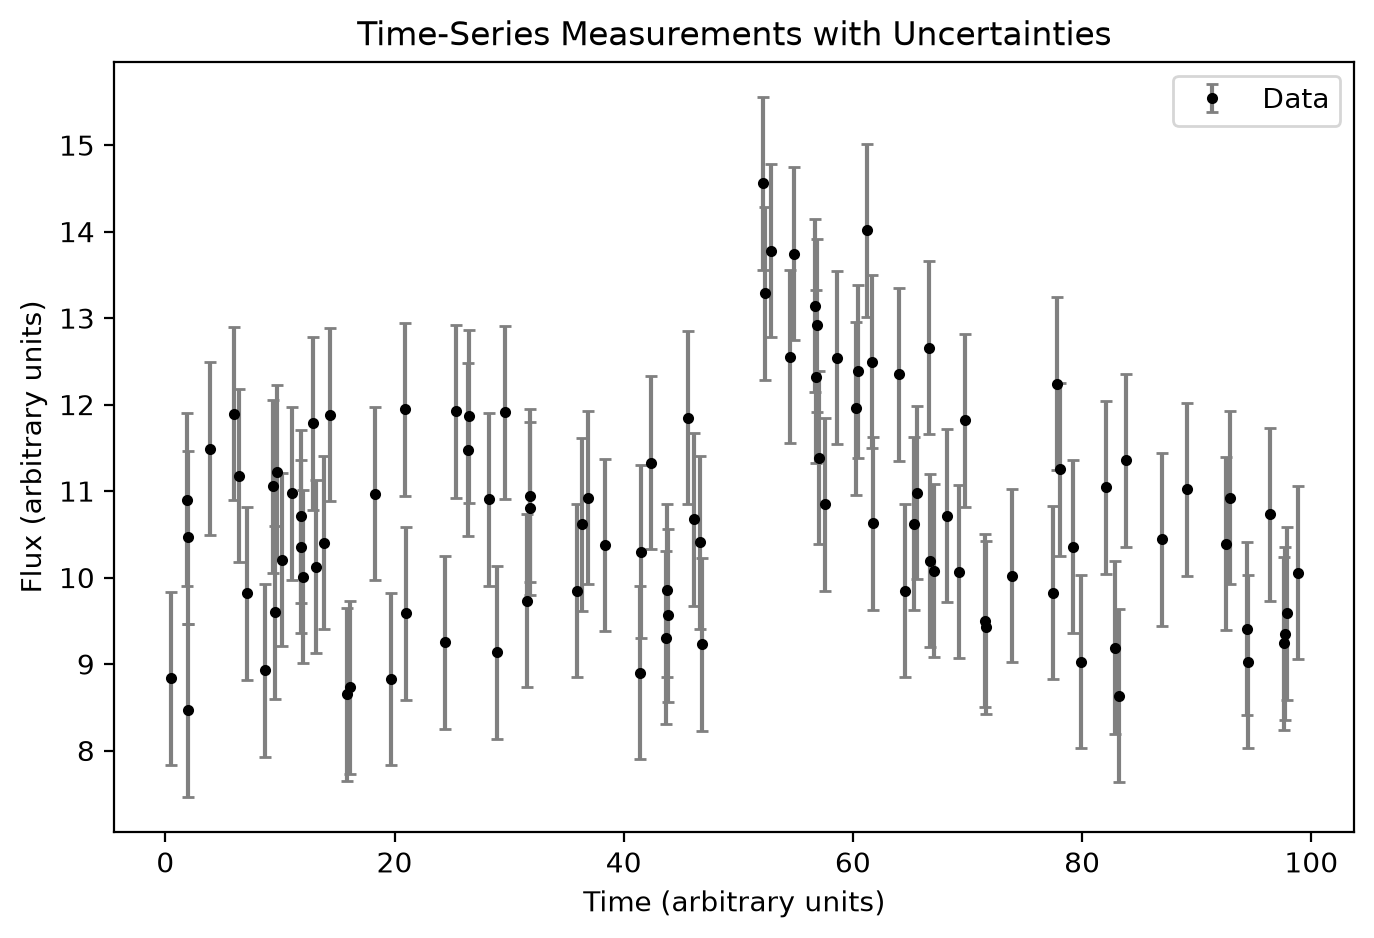

In [6]:
# ---Pt.1---
data = np.load("C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/student_folders/aaron_hawley/homeworks/hw_data/hw5_data_1.npy")
time = data[:,0]
flux = data[:,1]
yerr = data[:,2]

plt.figure(figsize=(8, 5))
plt.errorbar(time, flux, yerr=yerr, fmt='.k', ecolor='gray', capsize=2, label='Data')
plt.xlabel('Time (arbitrary units)')
plt.ylabel('Flux (arbitrary units)')
plt.title('Time-Series Measurements with Uncertainties')
plt.legend()
plt.show()


In [7]:
# ---Pt.2---
def burst_model(t, b, A, t0, alpha):
    dt = t - t0
    exponent = np.clip(-alpha * dt, -500, 500)
    y = np.where(t < t0, b, b + A * np.exp(exponent))
    return y

def log_prior(theta):
    b, A, t0, ln_alpha = theta
    if (0 <= b <= 50) and (0 <= A <= 50) and (0 <= t0 <= 100) and (-5 <= ln_alpha <= 5):
        return 0.0
    return -np.inf

def log_likelihood(theta, t, flux, yerr):
    b, A, t0, ln_alpha = theta
    alpha = np.exp(ln_alpha)
    model = burst_model(t, b, A, t0, alpha)
    inv_sigma2 = 1.0 / (yerr ** 2)
    return -0.5 * np.sum((flux - model) ** 2 * inv_sigma2 - np.log(inv_sigma2) + np.log(2 * np.pi))

def log_posterior(theta, t, flux, yerr):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, t, flux, yerr)

In [8]:
# ---Pt.3---
ndim = 4
nwalkers = 32
nsteps = 25000

np.random.seed(42)
p0 = np.zeros((nwalkers, ndim))
p0[:, 0] = np.random.uniform(5, 15, nwalkers)
p0[:, 1] = np.random.uniform(10, 30, nwalkers)
p0[:, 2] = np.random.uniform(20, 60, nwalkers)
p0[:, 3] = np.random.uniform(-1, 1, nwalkers)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior, args=(time, flux, yerr))
sampler.run_mcmc(p0, nsteps, progress=True)

100%|██████████| 25000/25000 [00:50<00:00, 496.12it/s]


State([[10.28496377  3.69813686 51.14013052 -2.08442292]
 [10.17851743  6.45876833 47.04321897 -2.03580827]
 [10.78399254  6.0872837  11.6468704   4.16958901]
 [10.39654552  5.62114992 48.19560867 -2.29942091]
 [10.31574874  5.92939728 49.11351342 -1.9966318 ]
 [10.4510666   4.83682179 48.18706935 -2.20282397]
 [10.36667962  6.74639998 47.94925338 -1.98871976]
 [10.36773615  5.65175374 48.70127784 -1.98822435]
 [10.38599203  9.91738138 47.60340223 -1.68227025]
 [10.40660068  4.23936257 51.1645428  -2.20083265]
 [10.31526852  5.28878475 50.41472483 -1.98573973]
 [10.30544323  6.73627713 49.22958282 -1.75129533]
 [10.24591035  4.44221619 49.39685887 -2.27801605]
 [10.25700515  6.09974954 47.12742417 -2.30504418]
 [10.23698896  5.26760872 49.97914569 -2.27145506]
 [10.08212783 11.91882513 47.01174751 -1.65828298]
 [10.37035805  6.4178373  50.04625879 -1.71961642]
 [10.01614526  6.90603604 48.87836998 -1.9644956 ]
 [10.20091081  3.54396755 51.28444126 -2.42321892]
 [10.42366675  6.72970479

In [9]:
# ---Pt.4---
tau = sampler.get_autocorr_time(quiet=True)
burnin = int(2 * np.max(tau))
thin = int(0.5 * np.min(tau) / 4)

print(f"Estimated autocorrelation times: {tau}")
print(f"Using burn-in: {burnin}, thinning: {thin}")

flat_samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)

Estimated autocorrelation times: [ 81.07065664 159.71869187 170.58596459 179.6647498 ]
Using burn-in: 359, thinning: 10


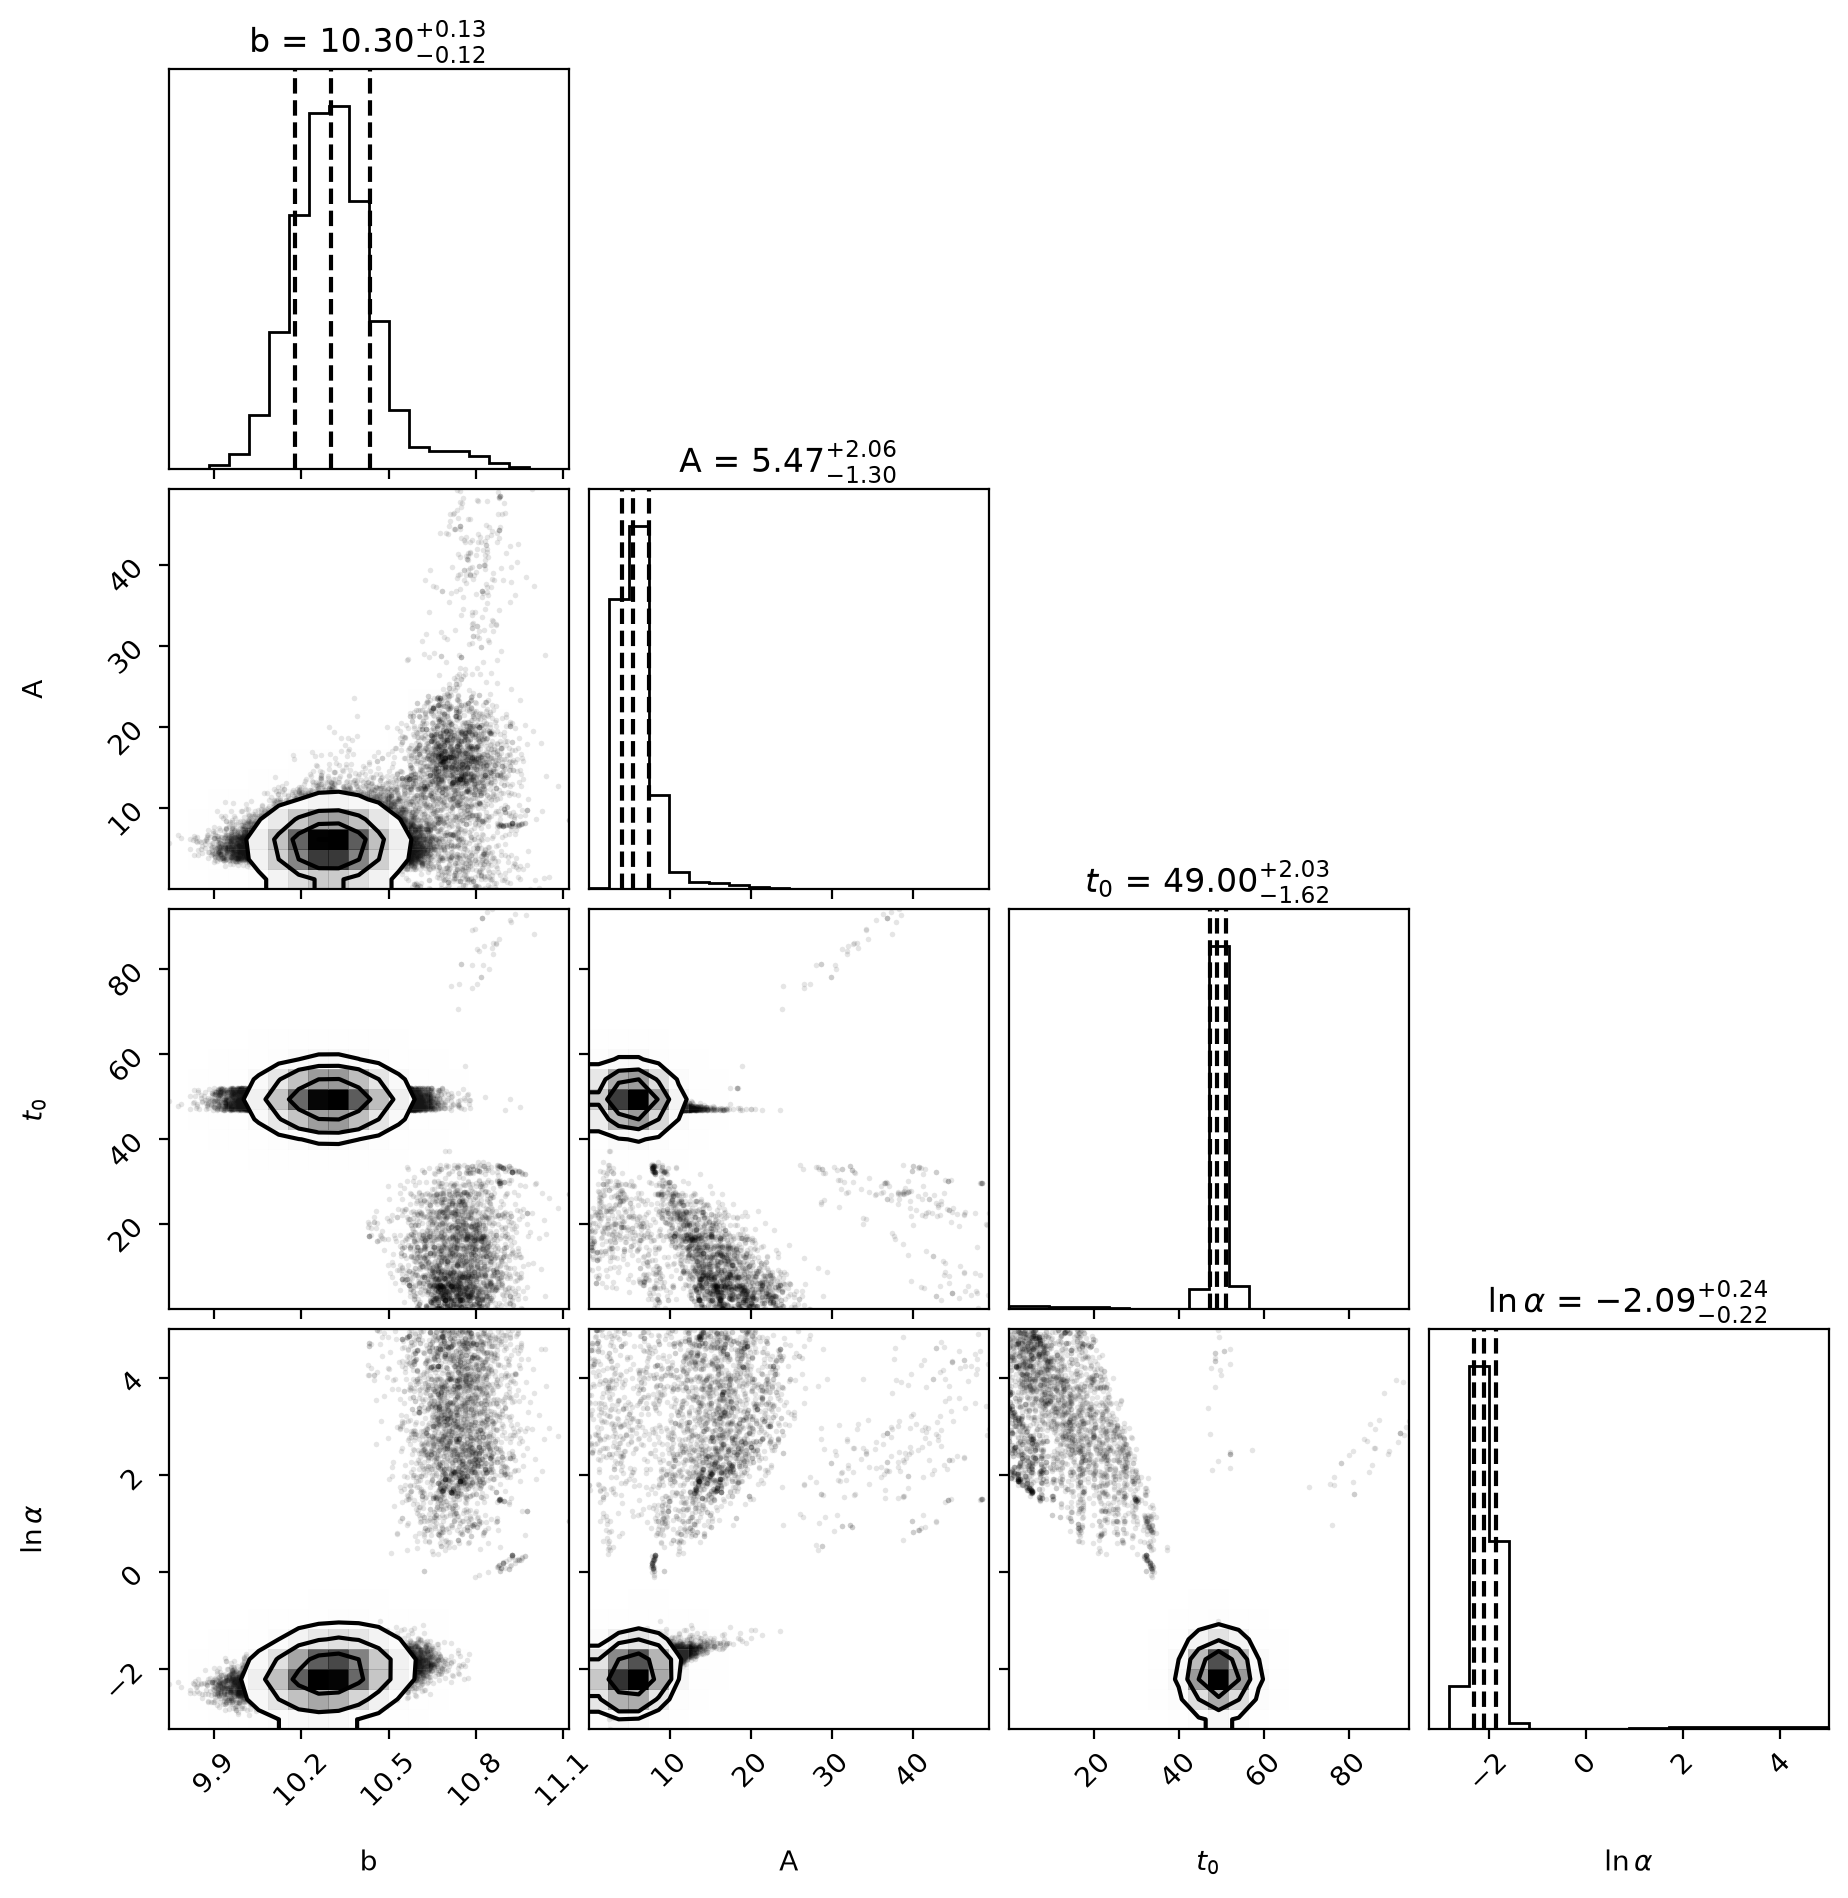

In [11]:
# ---Pt.5---
fig = corner.corner(
    flat_samples,
    labels=["b", "A", "$t_0$", r"$\ln\alpha$"],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".2f",
    title_kwargs={"fontsize": 12},
    smooth=1
)
plt.show()

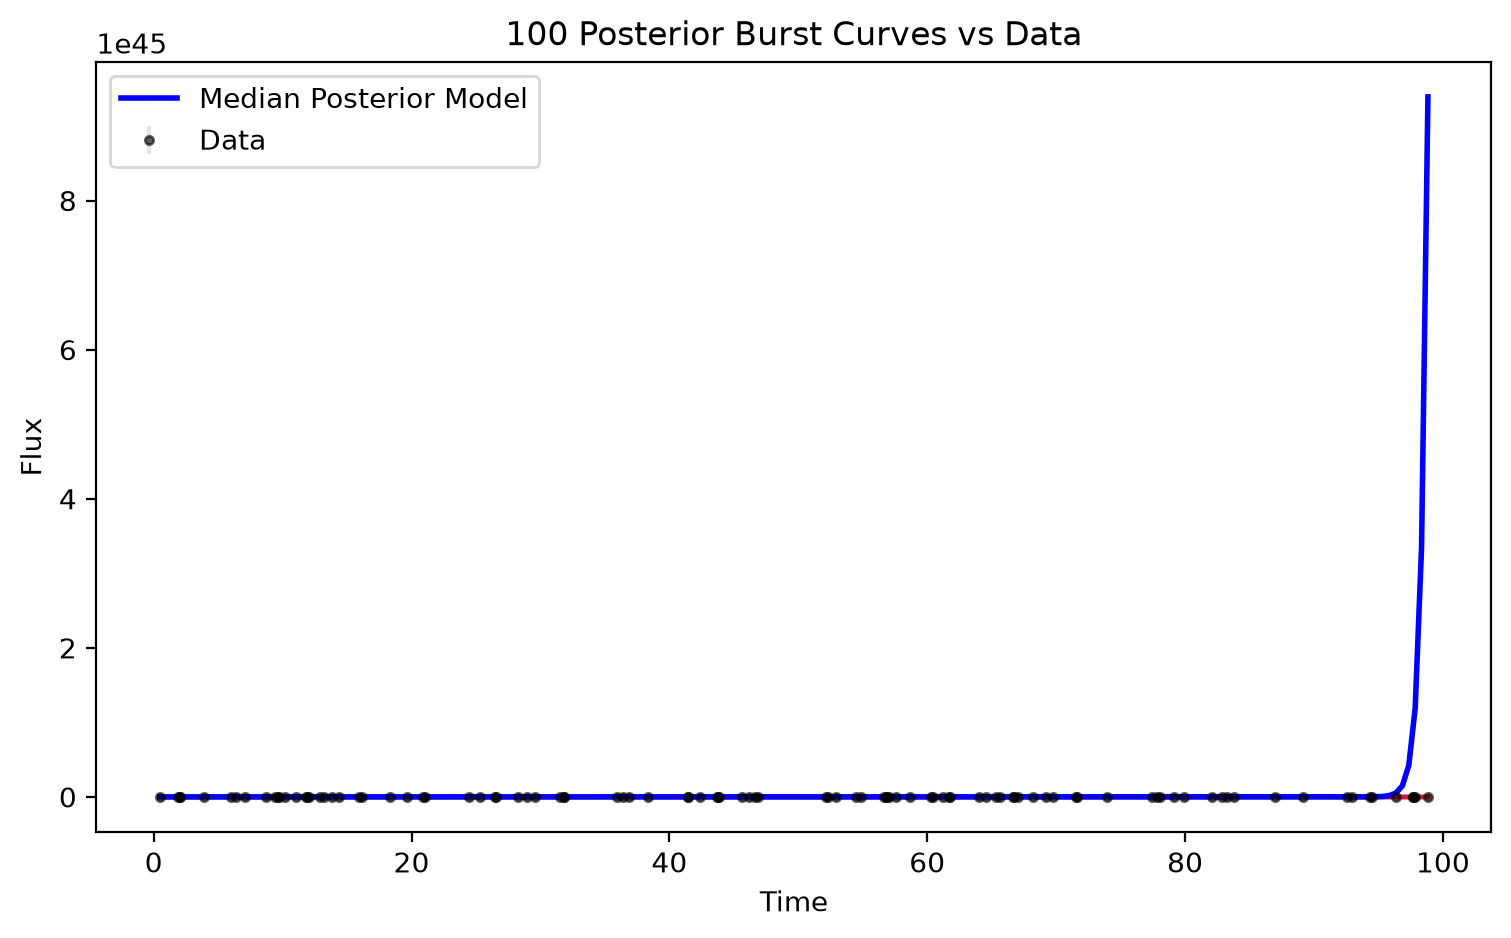

In [12]:
# ---Pt.6---
plt.figure(figsize=(9, 5))
plt.errorbar(time, flux, yerr=yerr, fmt='.k', ecolor='lightgray', alpha=0.6, label='Data')

random_indices = np.random.choice(len(flat_samples), size=100, replace=False)
t_grid = np.linspace(time.min(), time.max(), 200)

for idx in random_indices:
    b_s, A_s, t0_s, ln_alpha_s = flat_samples[idx]
    alpha_s = np.exp(ln_alpha_s)
    model_curve = burst_model(t_grid, b_s, A_s, t0_s, alpha_s)
    plt.plot(t_grid, model_curve, color='crimson', alpha=0.05)

plt.plot(t_grid, burst_model(t_grid, *[np.median(flat_samples[:, i]) for i in range(4)]), 
         color='blue', lw=2, label='Median Posterior Model')

plt.xlabel('Time')
plt.ylabel('Flux')
plt.title('100 Posterior Burst Curves vs Data')
plt.legend()
plt.show()

In [14]:
# ---Pt.7---
def gauss_model(t, b, A, t0, ln_sigmaW):
    sigmaW = np.exp(ln_sigmaW)
    return b + A * np.exp(-((t - t0) ** 2) / (2 * sigmaW ** 2))

def ptform_burst(u):
    theta = np.empty_like(u)
    theta[0] = u[0] * 50.0
    theta[1] = u[1] * 50.0
    theta[2] = u[2] * 100.0
    theta[3] = u[3] * 10.0 - 5.0
    return theta

def loglike_burst(theta):
    if log_prior(theta) == -np.inf:
        return -np.inf
    return log_likelihood(theta, time, flux, yerr)

sampler_b = dynesty.NestedSampler(loglike_burst, ptform_burst, ndim=4, sample='rwalk', bootstrap=0)
sampler_b.run_nested(print_progress=False)
res_b = sampler_b.results

def ptform_gauss(u):
    theta = np.empty_like(u)
    theta[0] = u[0] * 50.0
    theta[1] = u[1] * 50.0 
    theta[2] = u[2] * 100.0
    theta[3] = u[3] * 4.0 - 2.0 
    return theta

def loglike_gauss(theta):
    b, A, t0, ln_sigmaW = theta
    if not ((0 <= b <= 50) and (0 <= A <= 50) and (0 <= t0 <= 100) and (-2 <= ln_sigmaW <= 2)):
        return -np.inf
    sigmaW = np.exp(ln_sigmaW)
    model = gauss_model(time, b, A, t0, ln_sigmaW)
    inv_sigma2 = 1.0 / (yerr ** 2)
    return -0.5 * np.sum((flux - model) ** 2 * inv_sigma2 - np.log(inv_sigma2) + np.log(2 * np.pi))

sampler_g = dynesty.NestedSampler(loglike_gauss, ptform_gauss, ndim=4, sample='rwalk', bootstrap=0)
sampler_g.run_nested(print_progress=False)
res_g = sampler_g.results

lnZ_burst = res_b.logz[-1]
lnZ_gauss = res_g.logz[-1]
bayes_factor = np.exp(lnZ_burst - lnZ_gauss)

print(f"Log Evidence (Burst Model): {lnZ_burst:.2f}")
print(f"Log Evidence (Gaussian Model): {lnZ_gauss:.2f}")
print(f"Bayes Factor (Burst vs. Gaussian): {bayes_factor:.4e}")

if bayes_factor > 1:
    print("The burst model is favored over the Gaussian model")
else:
    print("The Gaussian model is favored over the burst model")

Log Evidence (Burst Model): -154.84
Log Evidence (Gaussian Model): -159.52
Bayes Factor (Burst vs. Gaussian): 1.0838e+02
The burst model is favored over the Gaussian model
